# <span style="color:green"> Numerical Simulation Laboratory (NSL) </span>
## <span style="color:blue">  Numerical exercises 2</span>

In [1]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import math

# Importance sampling
Suppose we have the following integral and that we want to evaluate it 
\begin{equation}
I= \int g(x')p(x') dx'
\end{equation}
A different probability distribution can be introduced into the integral as follows
\begin{equation}
I= \int \Big[ \frac{g(x')f(x')}{d(x')} \Big] d(x') dx'
\end{equation}
The variance of I when $d(x)$ is used becomes
\begin{equation}
Var[I]_d = \int \Big[ \frac{g(x')f(x')}{d(x')} \Big]^2 d(x') dx' -I^2
\end{equation}
I choose d(x) as the function that minimises the variance ( with normalisation constraints). Through the Lagrangian method, we obtain 
\begin{equation}
d(x) = \frac{g(x)p(x)}{I}
\end{equation}
Hence, we just need to sample a series of $x_i$ from $d(x)$ and costruct the sum 
\begin{equation}
G_N = \frac{1}{N} \sum_{i=1}^N \frac{g(x_i)p(x_i)}{d(x_i)} = \frac{1}{N} \sum_{i=1}^N I = I
\end{equation}

## Remarks

- Notice that if we could actually sample from $d(x) = \dfrac{g(x)p(x)}{I}$, then for every $x_i$ we would have

$$
\frac{g(x_i)p(x_i)}{d(x_i)} = I ,
$$

deterministically. This means the variance would be exactly zero, even for $N=1$. This confirms that the derivation is correct.

- However, there is a catch: to construct $d(x)$ we already need to know $I$, since $I$ appears in its own definition. So this "optimal" $d(x)$ cannot actually be sampled from in practice , it is a theoretical benchmark, showing that a perfect importance sampling density would eliminate all variance.

- In real applications we instead choose a $d(x)$ that:
  - is easy to sample from ,
  - mimics the shape of $g(x)p(x)$, peaking where the integrand is largest.

This does not eliminate the variance, but it typically produces a large variance reduction compared to uniform sampling — which is exactly what we observe when comparing the two integral estimates.

---
---

# Exercise 02.1

## Result

To solve this first task, I used two methods:
1. sampling from a uniform distribution on $[0,1]$;
2. using importance sampling (i.e. sampling from a non-uniform probability density on $[0,1]$).

**Method 1 — Uniform sampling**

I used the same workflow as in the first exercise. Consider the integral

$$
I = \int_{[0,1]} g(x')\,p(x')\,dx'
$$

where $p(x')$ is the flat (uniform) distribution on $[0,1]$ and $g(x')$ is the original integrand.

I sample $L$ numbers from $p(x)$, where $L = \dfrac{\text{throws}}{\text{blocks}} = \dfrac{10^6}{10^2} = 10^4$, and I estimate the integral with

$$
G_L = \frac{1}{L}\sum_{i=1}^{L} g(x_i).
$$

**Method 2 — Importance sampling**

Here I followed the theoretical derivation above, looking for a distribution $d(x)$ that resembles the shape of $g(x)p(x)$. I chose the Taylor expansion of $g(x)$ around $x=1$ (i.e. its linear approximation), which leads to

$$
d(x) = 2(1-x).
$$

After sampling from $d(x)$, the rest of the workflow (data blocking, averaging, error estimation) is identical to Method 1.

**Comparison**

In the following graph, I plot the estimated integral obtained with the two methods as a function of the number of blocks.

From the data, we observe that both methods converge to the exact value $I=1$; however, importance sampling shows a smaller statistical uncertainty (lower variance) than uniform sampling, as expected.

---

 **Exercise**
- Compute the following 1D integral via Monte Carlo 
$$I = \int_0^1 \frac{\pi}{2}\cos(\pi x/2) dx = 1$$

1. sampling a uniform distribution in $[0,1]$
2. using importance sampling (i.e. sampling a non-uniform probability in $[0,1]$)

<span style="color:red">Show a picture of both your estimations of $I$</span> and their uncertainties with a large number of *throws* $M$ (e.g. $M\ge 10^4$) as a function of the number of blocks, $N$</font>. 

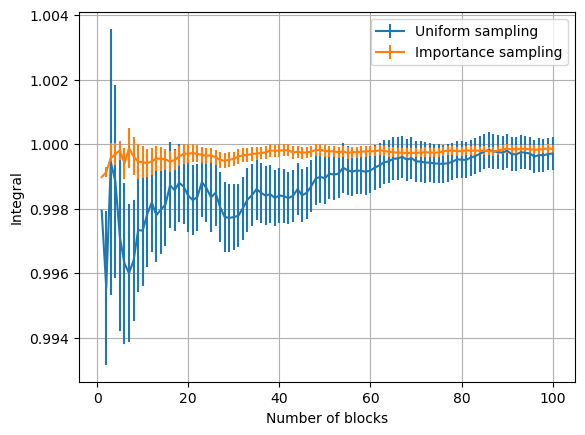

In [4]:
data1 = np.loadtxt("data1.txt")
data2 = np.loadtxt("data2.txt")

x1 = data1[:,0]
mean1 = data1[:,1]
err1 = data1[:,2]

x2 = data2[:,0]
mean2 = data2[:,1]
err2 = data2[:,2]



plt.errorbar(x1, mean1, yerr=err1, label="Uniform sampling")
plt.errorbar(x2, mean2, yerr=err2, label="Importance sampling")
plt.xlabel("Number of blocks")
plt.ylabel("Integral")
plt.legend()
plt.grid(True)

plt.show()

# Exercise 02.2

### Result

In this second part of the second simulation exercise, I studied two kinds of random walks: discrete and continuous.

**Discrete random walk** <br>
To implement the discrete random walk, I defined three increment vectors ($\pm 1$ along each axis):

```cpp
int incrementox_[6] = {1, -1, 0, 0, 0, 0};
```

At each step, a random index $i \in \{0, \dots, 5\}$ is drawn uniformly, and the walker's position is updated as:

```cpp
x[k] = x[k-1] + incrementox_[indice];
```

This corresponds to moving by $\pm 1$ along one of the three Cartesian axes, each with probability $1/6$. I repeated this process for 100 steps.

To estimate the mean square distance from the starting point after $N$ steps.
I performed $M = 10^4$ independent random walks, divided into 100 blocks of $10^2$ walks each. For each block, I computed the average of the squared distance $r^2$, and used data blocking to estimate $\sqrt{\langle r^2(N)\rangle}$ and its uncertainty as a function of the number of steps $N$.

**Continuous random walk** <br>
To perform a step, I sampled a point on a sphere of unit radius, with coordinates expressed in spherical form this requires sampling only two angles ($\theta$, $\phi$) to determine the direction
```cpp
double cos_theta = 1.0 - 2.0 * rnd.Rannyu(); 
double theta = acos(cos_theta);             
double phi = 2.0 * M_PI * rnd.Rannyu();  
```
     
I repeated this process for 100 steps.

As in the discrete case, to estimate the mean square distance from the starting point after $N$ steps.
I performed $M = 10^4$ independent random walks, divided into 100 blocks of $10^2$ walks each, and computed the block-averaged $\sqrt{\langle r^2(N)\rangle}$ with data blocking, as a function of the number of steps $N$.

**Results** <br>
The first two graphs confirm the theoretical prediction: the data points (blue dots) closely follow the theoretical curve

$$
\sqrt{\langle r^2(N) \rangle} = \sqrt{N},
$$

which is the expected scaling for a random walk with unit step length. This confirms that the root-mean-square displacement grows as the square root of the number of steps, in both the discrete and continuous cases.

**Bonus** <br>
The last two graphs show the trajectories of 7 independent 3D random walks (discrete and continuous, respectively).

---

**Exercise**
1. on a cubic lattice with lattice constant $a=1$; at each discrete time the walker makes a forward or backward step of length equal to $a$ in one of the 3 principal directions of the lattice: $x$, $y$ or $z$
2. in the continuum, at each discrete time the walker makes a step of length equal to $a(=1)$ along a **random direction** obtained by sampling **uniformly** the solid angle: $\theta \in [0,\pi]$ and $\phi \in [0,2\pi]$

<span style="color:red">Show a picture of $\sqrt{\langle |\vec{r}_N|^2 \rangle_{RW}}$ for both RWs</span>, with their statistical uncertainties, as function of the step $i\in [0,10^2]$.  


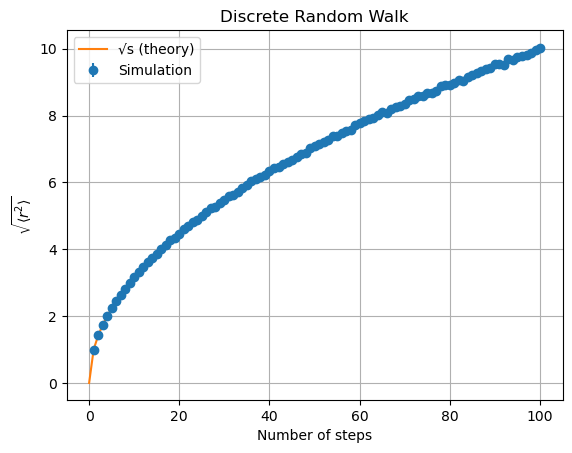

In [4]:
data1 = np.loadtxt("data4.txt")

x1 = data1[:,0]
mean1 = data1[:,1]
err1 = data1[:,2]

# vettore N da 0 a 100 con 100 punti
N = np.linspace(0, 100, 100)

# radice quadrata
sqrt_N = np.sqrt(N)

plt.errorbar(x1, mean1, yerr=err1, fmt='o', label="Simulation")
plt.plot(N, sqrt_N, label="√s (theory)")
plt.title("Discrete Random Walk")
plt.xlabel("Number of steps")
plt.ylabel(r"$\sqrt{\langle r^2 \rangle}$")
plt.grid(True)
plt.legend()

plt.show()

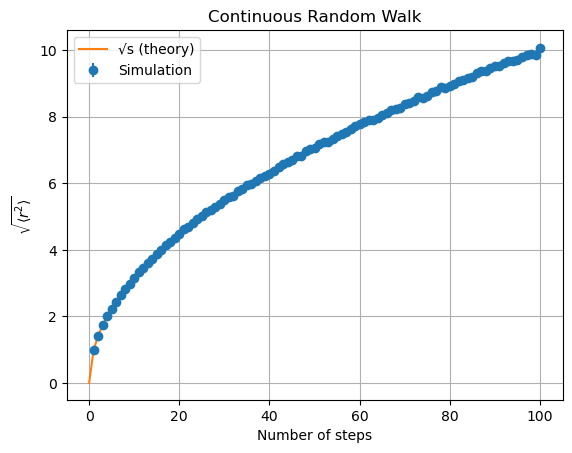

In [6]:
data2 = np.loadtxt("data5.txt")

x2 = data2[:,0]
mean2 = data2[:,1]
err2 = data2[:,2]


# vettore N da 0 a 100 con 100 punti
N2 = np.linspace(0, 100, 100)

# radice quadrata
sqrt_N2 = np.sqrt(N)

plt.errorbar(x2, mean2, yerr=err2, fmt='o', label="Simulation")
plt.plot(N2, sqrt_N2, label="√s (theory)")
plt.title("Continuous Random Walk")
plt.xlabel("Number of steps")
plt.ylabel(r"$\sqrt{\langle r^2 \rangle}$")
plt.grid(True)
plt.legend()

plt.show()

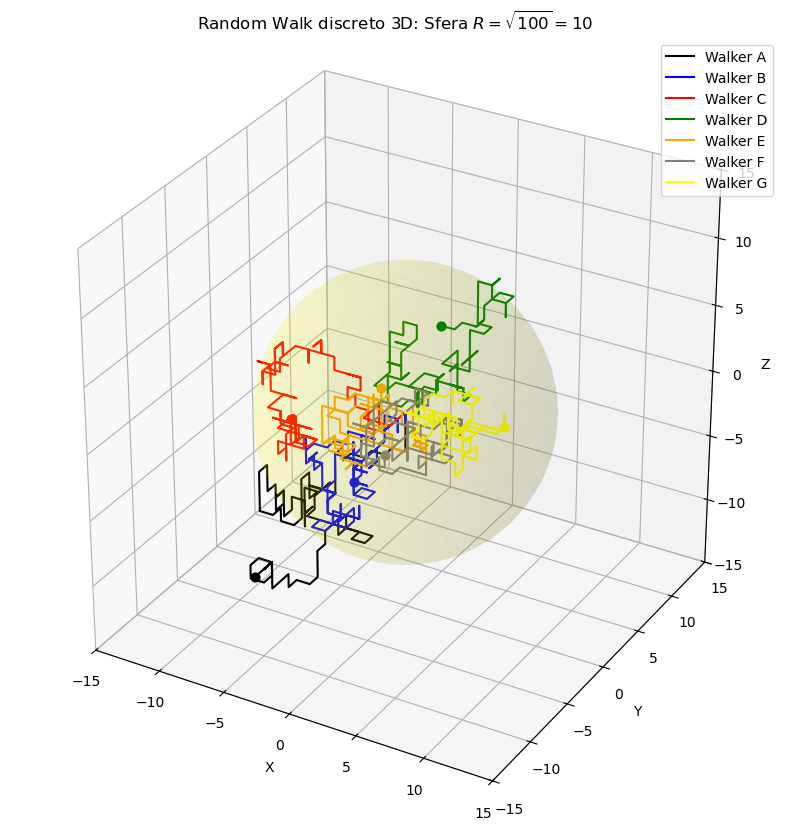

In [23]:
import matplotlib.pyplot as plt
import numpy as np

def plot_final_walks(filename, n_steps=100):
    walks = {'A': [], 'B': [], 'C': [], 'D': [] , 'E': [], 'F': [] , 'G': []}
    
    # 1. Lettura dati dal file
    with open(filename, 'r') as f:
        lines = f.readlines()
        
    i = 0
    while i < len(lines):
        line = lines[i].strip()
        if not line: i += 1; continue
        try:
            num_atoms = int(line)
            i += 2 
            for _ in range(num_atoms):
                if i < len(lines):
                    parts = lines[i].split()
                    if parts[0] in walks:
                        walks[parts[0]].append([float(parts[1]), float(parts[2]), float(parts[3])])
                    i += 1
        except: i += 1

    fig = plt.figure(figsize=(10, 10))
    ax = fig.add_subplot(111, projection='3d')

    # 2. Sfera di raggio sqrt(N)
    r = np.sqrt(n_steps) # Se n_steps=100, r=10.0
    u, v = np.mgrid[0:2*np.pi:50j, 0:np.pi:25j]
    x_sphere = r * np.cos(u) * np.sin(v)
    y_sphere = r * np.sin(u) * np.sin(v)
    z_sphere = r * np.cos(v)
    
    # La disegniamo in giallo trasparente
    ax.plot_surface(x_sphere, y_sphere, z_sphere, color='yellow', alpha=0.1, linewidth=0)
    # Aggiungiamo un cerchio sull'equatore per verificare il raggio 10
    ax.plot(x_sphere[:,0], y_sphere[:,0], 0, color='gray', lw=0.5, alpha=0.5) 

    # 3. Disegno dei 4 Walker
    colors = {'A': 'black', 'B': 'blue', 'C': 'red', 'D': 'green', 'E': 'orange', 'F': 'gray', 'G': 'yellow'}
    for name, points in walks.items():
        if points:
            path = np.array(points)
            ax.plot(path[:, 0], path[:, 1], path[:, 2], label=f'Walker {name}', color=colors[name], lw=1.5)
            ax.scatter(path[-1, 0], path[-1, 1], path[-1, 2], color=colors[name], s=40)

    # 4. TRUCCO PER IL RAGGIO: Impostazioni assi e proporzioni
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('Z')
    ax.set_title(rf'Random Walk discreto 3D: Sfera $R = \sqrt{{100}} = 10$')
    
    # Forziamo gli assi a essere uguali (fondamentale!)
    limit = 15 # Mostriamo un box da -15 a 15
    ax.set_xlim(-limit, limit)
    ax.set_ylim(-limit, limit)
    ax.set_zlim(-limit, limit)
    
    # Questo comando rende la sfera "rotonda" e non schiacciata
    ax.set_box_aspect([1, 1, 1]) 
    
    ax.legend()
    plt.show()

# Esegui
plot_final_walks('trajectory.xyz', n_steps=100)
     
   

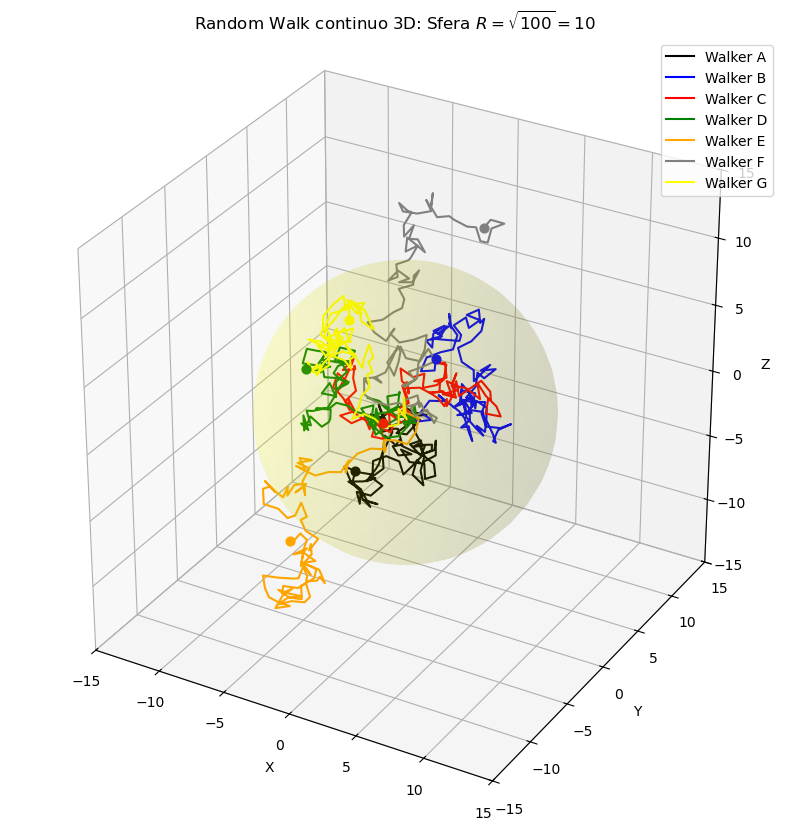

In [56]:
import matplotlib.pyplot as plt
import numpy as np

def plot_final_walks(filename, n_steps=100):
    walks = {'A': [], 'B': [], 'C': [], 'D': [] , 'E': [], 'F': [] , 'G': []}
    
    # 1. Lettura dati dal file
    with open(filename, 'r') as f:
        lines = f.readlines()
        
    i = 0
    while i < len(lines):
        line = lines[i].strip()
        if not line: i += 1; continue
        try:
            num_atoms = int(line)
            i += 2 
            for _ in range(num_atoms):
                if i < len(lines):
                    parts = lines[i].split()
                    if parts[0] in walks:
                        walks[parts[0]].append([float(parts[1]), float(parts[2]), float(parts[3])])
                    i += 1
        except: i += 1

    fig = plt.figure(figsize=(10, 10))
    ax = fig.add_subplot(111, projection='3d')   
    # 2. Sfera di raggio sqrt(N)
    r = np.sqrt(n_steps) # Se n_steps=100, r=10.0
    u, v = np.mgrid[0:2*np.pi:50j, 0:np.pi:25j]
    x_sphere = r * np.cos(u) * np.sin(v)
    y_sphere = r * np.sin(u) * np.sin(v)
    z_sphere = r * np.cos(v)
    
    # La disegniamo in giallo trasparente
    ax.plot_surface(x_sphere, y_sphere, z_sphere, color='yellow', alpha=0.1, linewidth=0)
    # Aggiungiamo un cerchio sull'equatore per verificare il raggio 10
    ax.plot(x_sphere[:,0], y_sphere[:,0], 0, color='gray', lw=0.5, alpha=0.5) 

    # 3. Disegno dei 4 Walker
    colors = {'A': 'black', 'B': 'blue', 'C': 'red', 'D': 'green', 'E': 'orange', 'F': 'gray', 'G': 'yellow'}
    for name, points in walks.items():
        if points:
            path = np.array(points)
            ax.plot(path[:, 0], path[:, 1], path[:, 2], label=f'Walker {name}', color=colors[name], lw=1.5)
            ax.scatter(path[-1, 0], path[-1, 1], path[-1, 2], color=colors[name], s=40)

    # 4. TRUCCO PER IL RAGGIO: Impostazioni assi e proporzioni
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('Z')
    ax.set_title(rf'Random Walk continuo 3D: Sfera $R = \sqrt{{100}} = 10$')
        # Forziamo gli assi a essere uguali (fondamentale!)
    limit = 15 # Mostriamo un box da -15 a 15
    ax.set_xlim(-limit, limit)
    ax.set_ylim(-limit, limit)
    ax.set_zlim(-limit, limit)
    
    # Questo comando rende la sfera "rotonda" e non schiacciata
    ax.set_box_aspect([1, 1, 1]) 
    
    ax.legend()
    plt.show()

# Esegui
plot_final_walks('trajectory2.xyz', n_steps=100)
    
